In [1]:
# general
from glob import glob
from os import path

# data handling, randomness, and display
import pandas as pd
import numpy as np
from random import random, choice, choices, randint, uniform, shuffle
from IPython.core.display import Image, display

# img handling
import cv2

# label generation
from genalog.generation.content import CompositeContent, ContentType
from genalog.generation.document import DocumentGenerator
# label degredation
import genalog.degradation.effect as effect
from genalog.degradation.degrader import Degrader, ImageState


#### Generate a false collection name using bits from real collections

In [2]:
collection_data = pd.read_csv("./source/herbarium_list.csv",  error_bad_lines=False)
print("collection data size:",  collection_data.shape)
# load in GBIF data
occ = pd.read_csv("./source/0002205-210819072339941/occurrence.txt", 
                  sep='\t',
                  header=0,
                  low_memory=False)

occ = occ.dropna(axis=1, how='all')  # drop any columns which are entirely empty 
print("occurrence data size:",  occ.shape)

b'Skipping line 3383: expected 34 fields, saw 35\nSkipping line 3463: expected 34 fields, saw 36\nSkipping line 3487: expected 34 fields, saw 40\nSkipping line 3572: expected 34 fields, saw 39\nSkipping line 3639: expected 34 fields, saw 35\nSkipping line 3652: expected 34 fields, saw 35\nSkipping line 3678: expected 34 fields, saw 35\nSkipping line 3717: expected 34 fields, saw 36\nSkipping line 3752: expected 34 fields, saw 36\nSkipping line 3767: expected 34 fields, saw 35\nSkipping line 3771: expected 34 fields, saw 40\nSkipping line 4127: expected 34 fields, saw 49\nSkipping line 4244: expected 34 fields, saw 38\nSkipping line 4252: expected 34 fields, saw 36\nSkipping line 4261: expected 34 fields, saw 40\nSkipping line 4298: expected 34 fields, saw 40\n'


collection data size: (4343, 34)
occurrence data size: (41974, 130)


#### Generate false text body

In [3]:
def gen_collection_name():
    """
    produces on demand, faux collection names by randomly combinding elements from Index Herbariorum (downloaded on 8/22/21)
    """
    element_count=randint(0,5)
    element_names = choices(['organization', 'code', 'branch', 'department', 'section'], k=element_count)
    elements = []
    for element_name in element_names:
        element = collection_data.loc[collection_data[element_name].notnull()].sample()[element_name].iloc[0]
        element = ", ".join([s for s in element.split(',') if s])
        element = element.replace("/t", " ")
        elements.append(element)

    delim = choice([",", " ", ", ", " & ", " at ", " in "])
    name = delim.join(elements).strip()
    name = name.replace("  ", " ")
    
    return name

def gen_name():
    """
    produces on demand, faux label identification by randomly combining elements from GBIF occurrence search
    https://doi.org/10.15468/dl.xbkqg4
    (downloaded on 8/22/21)
    """
    element_name = choice(['acceptedScientificName', 'verbatimScientificName'])
    element = occ.loc[occ[element_name].notnull()].sample()[element_name].iloc[0]
    element = ", ".join([s for s in element.split(',') if s])
    element = element.replace("/t", " ")
    return element
    
def gen_body():
    """
    produces on demand, faux label body by randomly combining elements from GBIF occurrence search
    https://doi.org/10.15468/dl.xbkqg4
    (downloaded on 8/22/21)
    """
    element_count=randint(0,15)
    element_names = choices(['locality', 'locationRemarks',  'verbatimElevation', 
                             'verbatimLocality', 'verbatimEventDate', 'identifiedBy',
                             'verbatimElevation', 'decimalLatitude', 'decimalLongitude',
                             'county', 'stateProvince', 'habitat',
                             'associatedTaxa', 'continent', 'genus', 'family'], k=element_count)
    elements = []
    for element_name in element_names:
        element = str(occ.loc[occ[element_name].notnull()].sample()[element_name].iloc[0])
        element = ", ".join([s for s in element.split(',') if s])
        if element_name == "continent":
            element = " ".join([x.title() for x in element.split("_")])
        elements.append(element)
    
    # sometimes add one of the lifeStages to it
    if randint(1,10) ==1:
        elements.append(choice(occ.loc[occ['lifeStage'].notnull()]['lifeStage'].unique().tolist()))
    
    cleaned_elements = []
    for element in elements:
        element = str(element)
        delim = choice([" ", " ", ". ", ",", ", ", "; ", " & ", " at ", " in ", " or "])    
        element = delim.join([s.strip() for s in element.split(',') if s])
        element = delim.join([s.strip() for s in element.split('|') if s])
        element = delim.join([s.strip() for s in element.split(' ,') if s])
        element = element.replace("/t", " ")
        cleaned_elements.append(element)

    delim = choice([" ", " ", " ", ". ", ",", " ", ", ", " & ", " at ", " in ", " or "])
    body = delim.join(cleaned_elements).strip()
    body = body.replace("  ", " ")
    
    return body

def gen_content():
    coll = gen_collection_name()
    bold = choice([True, True, True, False])
    italic = choice([False, False, False, False, True])
    start = ""
    end = ""
    if bold:
        start = start + "<b>"
        end = end + "</b>"
    if italic:
        start = start + "<i>"
        end = end + "</i>"
    coll = start + coll + end
    coll = coll.strip()
    
    if (len(coll) < 40) & (randint(1,3) ==1):
        coll = coll.upper()

    name = gen_name()
    bold = choice([True, False, False, False])
    italic = choice([True, True, True, False])
    start = ""
    end = ""
    if bold:
        start = start + "<b>"
        end = end + "</b>"
    if italic:
        start = start + "<i>"
        end = end + "</i>"
    name = start + name + end
    name = name.strip()
    
    body = gen_body()
    if randint(1,3) ==1: # once in a while make it a very busy label
        body = body + gen_body() + gen_body()
    bold = choice([False, False, False, False, False, True])
    italic = choice([False, False, False, False, False, True])
    start = ""
    end = ""
    if bold:
        start = start + "<b>"
        end = end + "</b>"
    if italic:
        start = start + "<i>"
        end = end + "</i>"
    body = start + body + end
    body = body.strip()

    content = CompositeContent([coll, name, body], [ContentType.TITLE, ContentType.PARAGRAPH, ContentType.PARAGRAPH])
    return content
    

print("example collection name:", gen_collection_name())
print("example specimen ID:", gen_name())
print("example label body:", gen_body())

example collection name: 
example specimen ID: Juniperus communis var. depressa Pursh
example label body: Pottiaceae in 44.14636999905715 in USA; New York; Wyoming; ; Java in University of California Botanical Garden in Artemisia sp.


____

#### Instantiate a list of generators from which to randomly choose

Default genalog seems to want to produce an element for each style option, I'd rather generate one element by randomly selecting from the style options. Instead of instantiating a new generator class every time, create a list from which to choose.

In [4]:
doc_styles = []
for font_family in ["sans-serif", "monospace", "Calibri", "Times" "Segoe UI"]:
    for font_size in ["14px", "18px", "22px", "24px"]:
        for font_size_title in ["18px", "24px", "30px"]:
            for hyphenate in [True, False]:
                for width in [10, 15]:
                    if width == 15:
                        height = 10
                    else:
                        height = 15
                    for margin in ['0', '0.15' '0.35']:
                        DOCUMENT_STYLE = {
                                        "language": ["en_US"],
                                        "font_family": [font_family],
                                        "font_size": [font_size],
                                        "font_size_title": [font_size_title],
                                        "text_align": ["left"],
                                        "hyphenate": [hyphenate],
                                        "width":[width],
                                        "height":[height],
                                        "margin": [margin]
                                        }
                        doc_styles.append(DOCUMENT_STYLE)

generators = []
for style in doc_styles:
    document_generator = DocumentGenerator(template_path="./templates")
    document_generator.set_styles_to_generate(style)
    generators.append(document_generator)
del doc_styles

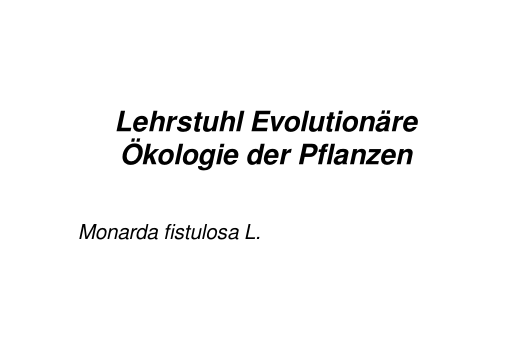

In [5]:
content = gen_content()
gen = choice(generators)

doc_gen = gen.create_generator(content, ["label.html.jinja"])
for doc in doc_gen:
    # however many pages it broke out into.. make it only one
    doc._document.pages = doc._document.pages[:1]
    image_byte = doc.render_png(split_pages=True, resolution=90, target=None)
    
display(Image(image_byte))

#### Instantiate a list of degraders from which to randomly choose


Similar to above, I'd like to randomly choose degredation per generated content. Instead of instantiating a new degrader class every time, create a list of them from which to choose.

In [6]:
morp_options = [{"kernel_shape":(7,7), "kernel_type":"plus"},
                {"kernel_shape":(5,1), "kernel_type":"ones"},
                {"kernel_shape":(1,5), "kernel_type":"ones"},
                {"kernel_shape":(4,4), "kernel_type":"ellipse"},
                {"kernel_shape":(5,5), "kernel_type":"upper_triangle"},
                {"kernel_shape":(3,3), "kernel_type":"plus"}]

degradations = []
for salt in [False, 0.1, 0.15, 0.2]:
    for pepper in [False, 0.0001, 0.001, 0.01, 0.05]:
        for overlay in [True, False]:
            for bleed_through in [True, False]:
                #None, 0.9, 0.3
                for blur in [False, 3, 5]:
                    for operation in [False, "open", "close", "both"]:
                        current_degradation = []
                        if operation:
                            if operation == "both":
                                for operation in ["open", "close"]:
                                    morph = choice(morp_options)
                                    morph["operation"] = operation
                                    op_obj = ("morphology", morph)
                                    current_degradation.append(op_obj)
                            else:
                                morph = choice(morp_options)
                                morph["operation"] = operation
                                op_obj = ("morphology", morph)
                                current_degradation.append(op_obj)
                        if blur:
                            blur_obj = ("blur", {"radius": blur})
                            current_degradation.append(blur_obj)
                        if bleed_through:
                            bleed_obj = ("bleed_through", {"src": ImageState.CURRENT_STATE,
                                                           "background": ImageState.ORIGINAL_STATE,
                                                           "alpha": choice([uniform(0.1, 0.25), uniform(0.05, 0.9)]),
                                                           "offset_x": randint(-5,2),
                                                           "offset_y": randint(-5,2)})
                            current_degradation.append(bleed_obj)
                        if pepper:
                            pepper_obj = ("pepper", {"amount": pepper})
                            current_degradation.append(pepper_obj)
                        if salt:
                            salt_obj = ("salt", {"amount": salt})
                            current_degradation.append(salt_obj)
                        # shuffle the order in which degradations are applied
                        shuffle(current_degradation)
                        if overlay: # be sure overlay is at the end if it is used
                            overlay_obj = ("overlay", {"src": ImageState.ORIGINAL_STATE,
                                                      "background": ImageState.CURRENT_STATE,})
                            current_degradation.append(overlay_obj)
                        if randint(1,3) < 3:  # frequently cull a few of them
                            new_len = len(current_degradation) - randint(2, 6)
                            if new_len > 0:
                                current_degradation[:new_len]
                        if current_degradation:  # if anything exists here.. append it to the list of options
                            degradations.append(current_degradation)
                            
degraders = [Degrader(x) for x in degradations]
del degradations
print(f"produced {len(degraders)} degraders")


def randomly_perturb(img):
    """
    applys random rotation and cropping
    """
    height, width = img.shape[:2] #532, 355
    empty_white = np.full_like(img, 255)

    if randint(1,3) == 1:
        center=tuple(np.array([height,width])/2)
        rot_mat = cv2.getRotationMatrix2D(center,uniform(-15,15),1.0)
        img = cv2.warpAffine(img, rot_mat, (height,width),  borderValue=(255,255,255))

    if randint(1,3) == 3:

        new_height = randint(height//1.5, height)
        new_width = randint(width//1.5, width)

        x_start = width//2 - new_width//2
        x_end = width//2 + new_width//2
        
        y_start = height//2 - new_height//2
        y_end = height//2 + new_height//2

        img = img[y_start:y_end, x_start:x_end]
        new_height, new_width = img.shape[:2]

        y_diff = height - new_height
        y_start = randint(0, y_diff)
        y_end = y_start + new_height

        x_diff = width - new_width
        x_start = randint(0, x_diff)
        x_end = x_start + new_width
        empty_white[y_start:y_end, x_start:x_end] = img
        img = empty_white
        
    return img


produced 959 degraders


Create a general function which ties all this togeather.

In [7]:
rotation_choices = [cv2.cv2.ROTATE_90_CLOCKWISE, cv2.cv2.ROTATE_90_COUNTERCLOCKWISE]
def gen_distorted_label(fn):
    # get the text content
    content = gen_content()
    # select which generator to use
    gen = choice(generators)
    # produce the base document
    doc_gen = gen.create_generator(content, ["label.html.jinja"])
    for doc in doc_gen:
        doc._document.pages = doc._document.pages[:1] # however many pages it broke out into.. make it only one
        src = doc.render_png(split_pages=True, resolution=90, target=None)

    # convert byte string into numpy array
    src = np.frombuffer(src, dtype='uint8')
    # pass numpy array into cv2
    src = cv2.imdecode(src, cv2.IMREAD_GRAYSCALE)
    # randomly perturb the image using cv2 methods (rotation & transformation/cropping)
    dst = randomly_perturb(src)
    # select which degrader ot use
    degrader = choice(degraders)
    dst = degrader.apply_effects(dst)
    # check if the image needs rotated
    height, width = dst.shape[:2]
    if height > width:
        dst = np.rot90(dst, choice([-1,1]))
        #dst = cv2.rotate(dst, choice(rotation_choices))
    cv2.imwrite(fn, dst)

#### Actually produce the label images

In [11]:
qty = 5000  # the number of images to produce
dst_folder = "./output"
start_num = len(glob(f"{dst_folder}/*.jpg"))
for i in range(start_num, start_num+qty):
    fn = f"{dst_folder}/{i}.jpg"
    gen_distorted_label(fn)